# QuLTSF: does a quantum layer improve long-term forecasting?

A reproduction of *QuLTSF: Long-Term Time Series Forecasting with Quantum
Machine Learning* (Chittoor, Griffin, Neufeld, Thompson, Gu;
[arXiv:2412.13769](https://arxiv.org/abs/2412.13769)).

This notebook walks through the paper's claim, reproduces its numbers, and
then asks whether the quantum circuit is what makes the model work. It runs
top to bottom on a CPU in a few minutes:

- **Live cells** load the real Weather data, run known-answer checks on the
  circuit simulator and the MerLin layer, and train three models briefly.
- **Stored results** come from the full runs (166 runs on an NVIDIA L4),
  read from `results/`. Each stored-result section says so.

Sections: 1 claim · 2 data and protocol · 3 the model in equations ·
4 sanity checks · 5 model walkthrough · 6 live experiment · 7 headline result ·
8 fair baselines · 9 controls · 10 robustness and uncertainty ·
11 photonic adaptation · 12 conclusion.

In [1]:
import json
import logging
import sys
import time
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

PAPER_DIR = Path.cwd()
REPO_ROOT = PAPER_DIR.parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from runtime_lib.config import deep_update, load_config
from runtime_lib.dtypes import resolve_config_dtypes

from papers.QuLTSF.lib import plotting, runner
from papers.QuLTSF.lib.data import build_dataloader, load_series, model_dtype
from papers.QuLTSF.lib.models import build_model, count_trainable_parameters
from papers.QuLTSF.lib.quantum_simulator import AmplitudeSELayer
from papers.QuLTSF.lib.training import per_window_errors

logging.getLogger().setLevel(logging.WARNING)
pd.set_option("display.precision", 4)
RESULTS = PAPER_DIR / "results"
NOTEBOOK_START = time.perf_counter()


def show(fig):
    # lib.plotting renders with the non-interactive Agg backend; show the PNG.
    import io

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(buffer.getvalue()))


print("torch", torch.__version__, "| CPU threads:", torch.get_num_threads(), "| CUDA used: no")

torch 2.12.1+cu130 | CPU threads: 7 | CUDA used: no


## 1. Problem statement and the paper's claim

**Task.** Long-term time series forecasting (LTSF): from the last $L$ values
of each of the 21 Weather variables, predict the next $T$ values. Zeng et al.
(2023) showed that one linear layer per horizon (Linear, NLinear, DLinear)
beats transformer forecasters on these benchmarks, so linear models are the
bar to clear.

**The paper's claims.**

| ID | Claim | Evidence in the paper |
|---|---|---|
| C1 | QuLTSF has lower test MSE and MAE than Linear, NLinear and DLinear at $L = 336$, $T \in \{96, 192, 336, 720\}$ | Table 1 (linear values quoted from Zeng et al.) |
| C2 | QuLTSF wins at every lookback $L$ for $T = 96$ and $720$ | Figs 2-3 |
| C3 | "Incorporating a hidden quantum layer yielded additional improvements" | Sec. 6, text only |

**Research questions, and what would weaken the claim.**

1. *Do the numbers reproduce?* Weakened if our QuLTSF test MSE differs from
   Table 1 by more than seed noise.
2. *Does QuLTSF beat linear models trained under the same conditions?*
   Weakened if the margin disappears once the baselines get the same
   pipeline, budget and seeds.
3. *Is the quantum circuit the reason?* Weakened if the same model **with
   the circuit removed** performs as well.

Question 3 is the one the paper never tested. Sections 8-9 test it.

## 2. Data, splits, metrics and evaluation protocol

**Data.** The LTSF Weather benchmark (Max Planck Institute for
Biogeochemistry, Jena, 2020): 52,696 rows at 10-minute steps, 21 variables,
target column `OT` last. It is used unmodified, as upstream does. The loader
checks the file's sha256.

**Splits.** Chronological 70 / 10 / 20 % train / validation / test, with the
upstream borders: the validation and test windows start $L$ rows before
their split boundary, so the first forecast target is the first row of the
split. A `StandardScaler` is fitted on the **training rows only** and applied
everywhere.

**Metrics.** Test MSE (primary) and MAE on the standardised data, averaged
over every window, channel and horizon step. Lower is better.

**Protocol (same for every model unless labelled).** Adam, learning rate
1e-4, batch 16, up to 100 epochs, early stopping on validation MSE with
patience 20, the paper's `type3` learning-rate decay, and the
best-validation checkpoint. Seeds 2021, 2022 and 2023. The test set is used
once, for the final score, and never for selection.

In [2]:
DEFAULTS = load_config(PAPER_DIR / "configs" / "defaults.json")


def paper_config(name, **training):
    # Resolved config for configs/<name>.json, as the shared runtime builds it.
    cfg = deep_update(deepcopy(DEFAULTS), load_config(PAPER_DIR / "configs" / f"{name}.json"))
    cfg["device"] = "cpu"
    cfg["data_root"] = str(REPO_ROOT / "data")
    cfg["training"].update(training)
    return resolve_config_dtypes(cfg)


cfg = paper_config("table1_qultsf_original")
series = load_series(cfg)
seq_len = cfg["dataset"]["sequence_length"]
pred_len = cfg["dataset"]["prediction_horizon"]
starts, ends = series.border_starts, series.border_ends
split_table = pd.DataFrame(
    {
        "first row": starts,
        "last row (excl.)": ends,
        "rows": [e - s for s, e in zip(starts, ends)],
        "windows (L=336, T=96)": [e - s - seq_len - pred_len + 1 for s, e in zip(starts, ends)],
    },
    index=["train", "validation", "test"],
)
print(f"{series.values.shape[0]} rows x {series.values.shape[1]} channels; target column: {series.columns[-1]}")
display(split_table)
train_rows = series.values[: ends[0]]
print("train-split mean (max |.|):", float(np.abs(train_rows.mean(axis=0)).max()))
print("train-split std  (range):  ", float(train_rows.std(axis=0).min()), "-", float(train_rows.std(axis=0).max()))

52696 rows x 21 channels; target column: OT


,first row,last row (excl.),rows,"windows (L=336, T=96)"
train,0,36887,36887,36456
validation,36551,42157,5606,5175
test,41821,52696,10875,10444


train-split mean (max |.|): 5.633950696861065e-15
train-split std  (range):   0.9999999999999998 - 1.0000000000000002


The training split is standardised exactly (mean 0, std 1 per channel); the
validation and test splits are not, as they should not be.

## 3. The model in equations

Each channel's history $x \in \mathbb{R}^{L}$ is processed separately, with
weights shared across channels.

1. **Expand.** $h = W_1 x + b_1 \in \mathbb{R}^{2^N}$ with $N = 10$, so
   $2^N = 1024$.
2. **Amplitude embedding.** $|\psi\rangle = \sum_k a_k |k\rangle$ with
   $a = h / \lVert h \rVert$: a normalised 1024-dimensional vector becomes a
   10-qubit state.
3. **Circuit.** $K = 3$ StronglyEntanglingLayers $U(\theta)$, with 3 angles
   per qubit per layer, so 90 parameters.
4. **Readout.** $z_i = \langle \psi | U^\dagger Z_i U | \psi \rangle$ for
   $i = 1, \dots, N$.
5. **Forecast.** $\hat y = W_2 z + b_2 \in \mathbb{R}^{T}$.

**Removing the circuit.** With $U = I$ the readout becomes
$z_i = \sum_k a_k^2 \, s_{ik}$ with $s_{ik} = \pm 1$: a fixed, signed sum
of squared, normalised features. That is a purely classical computation,
a *normalised quadratic readout*. Section 9 uses it as the control for
claim C3.

**Photonic counterpart** (Section 11). Replace the $2^{10}$ qubit amplitudes
with the $\binom{14}{4} = 1001$ collision-free states of 4 photons in 14
optical modes, the circuit with a trainable interferometer, and $\langle Z_i
\rangle$ with each mode's click probability. Click probabilities are also
quadratic forms of the state.

## 4. Known-answer sanity checks

Before trusting any result, check the pieces against independent answers.

**4a. The circuit simulator against PennyLane.** We simulate the circuit as
a batched state vector in PyTorch, which is much faster than the upstream
PennyLane model. Here both run on the same random inputs and weights.

In [3]:
import pennylane as qml

torch.manual_seed(0)
n_qubits, n_layers = 3, 3
layer = AmplitudeSELayer(n_qubits, n_layers, dtype=torch.float64)
features = torch.randn(5, 2**n_qubits, dtype=torch.float64)
dev = qml.device("default.qubit", wires=n_qubits)


@qml.qnode(dev, interface="torch", diff_method="backprop")
def reference(inputs, weights):
    qml.AmplitudeEmbedding(features=inputs, wires=range(n_qubits), normalize=True)
    qml.StronglyEntanglingLayers(weights=weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


ours = layer(features).detach()
theirs = torch.stack(reference(features, layer.weights.detach()), dim=-1)
print("max |ours - PennyLane| =", float((ours - theirs).abs().max()))

max |ours - PennyLane| = 1.1102230246251565e-16


**4b. The circuit-free readout equals the formula from Section 3.** With the
circuit set to `identity`, the layer must return $\sum_k a_k^2 s_{ik}$. Here
wire 0 is the most significant bit, as in PennyLane.

In [4]:
identity_layer = AmplitudeSELayer(n_qubits, n_layers, circuit="identity", dtype=torch.float64)
a = features / features.norm(dim=-1, keepdim=True)
bits = (torch.arange(2**n_qubits)[:, None] >> torch.arange(n_qubits - 1, -1, -1)) & 1
signs = (1 - 2 * bits).to(torch.float64)
print("max |identity layer - sum_k a_k^2 s_ik| =", float((identity_layer(features) - (a * a) @ signs).abs().max()))

max |identity layer - sum_k a_k^2 s_ik| = 0.0


**4c. Parameter counts** match the arithmetic for the paper's setting.
**4d. A no-training baseline.** "Repeat the last observed value" needs no
fitting, so it checks the split borders and target alignment. We score it
live on the full test set and compare with the stored full run.

In [5]:
qultsf = build_model(cfg, model_dtype(cfg))
linear = build_model(paper_config("table1_linear_classical"), model_dtype(cfg))
print("QuLTSF parameters:", count_trainable_parameters(qultsf), "(expected 336*1024+1024 + 90 + 10*96+96 = 346,234)")
print("Linear parameters:", count_trainable_parameters(linear), "(expected 336*96+96 = 32,352)")

persistence_cfg = paper_config("table1_persistence_classical")
persistence = build_model(persistence_cfg, model_dtype(persistence_cfg))
test_loader = build_dataloader(persistence_cfg, "test", series)
errors = per_window_errors(persistence, test_loader, torch.device("cpu"), "M")
runs = pd.read_csv(RESULTS / "run_metrics.csv")
stored = runs.loc[runs.run_id == "persistence_L336_T96_seed2021", "test_mse"].item()
print(f"persistence test MSE: live {errors['squared'].mean():.6f} | stored full run {stored:.6f}")

QuLTSF parameters: 346234 (expected 336*1024+1024 + 90 + 10*96+96 = 346,234)
Linear parameters: 32352 (expected 336*96+96 = 32,352)
persistence test MSE: live 0.259133 | stored full run 0.259133


All four checks pass: the simulator agrees with PennyLane to machine
precision, the circuit-free readout is exactly the classical formula, the
parameter counts match, and the live persistence score equals the stored
one. Persistence (MSE 0.259) is also far worse than every trained model, so
the forecasting task is not trivial.

## 5. Model walkthrough

The paper's model, built from `configs/table1_qultsf_original.json` by
`lib.models.build_model`, applied to one real training batch.

In [6]:
train_loader = build_dataloader(cfg, "train", series)
inputs, targets = next(iter(train_loader))
print("batch inputs :", tuple(inputs.shape), "= (batch, L, channels)")
print("batch targets:", tuple(targets.shape), "= (batch, T, channels)")
with torch.no_grad():
    rows = inputs.permute(0, 2, 1).reshape(-1, seq_len)
    expanded = qultsf.input_classical_layer(rows)
    readout = qultsf.hidden_quantum_layer(expanded)
    forecast = qultsf(inputs)
print("per-channel rows:", tuple(rows.shape), "-> expanded:", tuple(expanded.shape),
      "-> <Z_i>:", tuple(readout.shape), "-> forecast:", tuple(forecast.shape))
print("readouts lie in [-1, 1]:", bool(readout.abs().max() <= 1 + 1e-6))
breakdown = {name: p.numel() for name, p in qultsf.named_parameters()}
display(pd.Series(breakdown, name="parameters"))

batch inputs : (16, 336, 21) = (batch, L, channels)
batch targets: (16, 96, 21) = (batch, T, channels)
per-channel rows: (336, 336) -> expanded: (336, 1024) -> <Z_i>: (336, 10) -> forecast: (16, 96, 21)
readouts lie in [-1, 1]: True


input_classical_layer.weight     344064
input_classical_layer.bias         1024
hidden_quantum_layer.weights         90
output_classical_layer.weight       960
output_classical_layer.bias          96
Name: parameters, dtype: int64

Almost all of QuLTSF's 346k parameters sit in the input layer
($336 \times 1024$); the circuit has 90. Every channel of every window
becomes one 10-qubit state, so a batch of 16 windows is 336 circuits.

## 6. A small live experiment

This trains three models on the real data with the paper's settings
(T = 96, Adam, lr 1e-4, batch 16, seed 2021), through the same
`lib.runner.train_and_evaluate` used for the full runs. Each gets **one
epoch capped at 400 batches**, about 17% of an epoch, then a full
validation and test evaluation.

- QuLTSF (the paper's model)
- QuLTSF without its circuit (the Section 3 classical readout)
- Linear (the paper's main baseline)

**Reduction.** This is an execution and learning-speed check, not a
reproduction: the full Table 1 runs train for 25-72 epochs. Conclusions about
accuracy come from the stored full runs in Sections 7-10.

In [7]:
LIVE_BATCHES = 400
live_dir = PAPER_DIR / "outdir" / "notebook_live" / time.strftime("%Y%m%d-%H%M%S")
live = []
for label, name, stored_name in [
    ("QuLTSF", "table1_qultsf_original", "qultsf"),
    ("QuLTSF, no circuit", "ablation_identity_circuit_classical", "identity_circuit"),
    ("Linear", "table1_linear_classical", "linear"),
]:
    run_cfg = paper_config(name, epochs=1, max_batches_per_epoch=LIVE_BATCHES)
    run_dir = live_dir / name
    run_dir.mkdir(parents=True)
    (run_dir / "config_snapshot.json").write_text(json.dumps({"config": name, "max_batches_per_epoch": LIVE_BATCHES}))
    started = time.perf_counter()
    runner.train_and_evaluate(run_cfg, run_dir)
    metrics = json.loads((run_dir / "metrics.json").read_text())
    full = runs[(runs.model == stored_name) & (runs.seq_len == 336) & (runs.pred_len == 96)]
    live.append({
        "model": label,
        "live val MSE": metrics["val"]["mse"],
        "live test MSE": metrics["test"]["mse"],
        "full-budget test MSE (3 seeds, stored)": full.test_mse.mean(),
        "live seconds": time.perf_counter() - started,
    })
display(pd.DataFrame(live).set_index("model"))

,live val MSE,live test MSE,"full-budget test MSE (3 seeds, stored)",live seconds
model,,,,
QuLTSF,0.7428,0.5555,0.1561,69.0676
"QuLTSF, no circuit",0.7305,0.5210,0.1549,17.0914
Linear,0.4968,0.2053,0.1744,15.2187


**Observation.** After 400 batches, Linear is much closer to its full-budget
accuracy than either QuLTSF variant, which are both still far from theirs.
The circuit-free variant is ahead of QuLTSF at this point.

**Inference.** QuLTSF's expansion to 1024 normalised features is slow to
train, which is why the paper's budget (up to 100 epochs, patience 20)
matters for it, and why the baselines must get the same budget for a fair
comparison (Section 8).

**Remaining uncertainty.** One seed, a fraction of an epoch; no accuracy
ranking can be read from this cell.

**Claim impact.** None; this cell shows that the pipeline runs end to end.

## 7. Headline reproduction result (stored full runs)

*Stored results.* 52 runs (4 horizons × 4 trained models × 3 seeds, plus
persistence once per horizon), on an NVIDIA L4, read from
`results/comparison.json` (generated by `utils/compare_results.py`, which
has a read-only `--verify` mode) and `results/run_metrics.csv` (one row per
run).

**Sweep record.** The first Table 1 sweep hit its 4-hour job limit with 42
of 52 runs done. The other 10 ran unchanged in a retry sweep. All 52
planned runs completed and are counted once, but the sweep record keeps the
label *PARTIAL SWEEP* because the first coordinator never finished.

In [8]:
comparison = json.loads((RESULTS / "comparison.json").read_text())
fair = json.loads((RESULTS / "fair_comparison.json").read_text())
for plan in comparison["plan_coverage"]["plans"]:
    print(f"{plan['plan']}: {plan['observed_runs']}/{plan['expected_runs']} runs, {plan['sweep_label']}")

table1 = []
for block in comparison["table1"]:
    row = block["rows"]["qultsf"]
    table1.append({
        "T": block["T"],
        "QuLTSF MSE (ours)": row["mse_mean"], "seed std": row["mse_std"],
        "QuLTSF MSE (paper)": row["paper"][0],
        "delta": row["mse_mean"] - row["paper"][0],
        "QuLTSF MAE (ours)": row["mae_mean"], "QuLTSF MAE (paper)": row["paper"][1],
    })
display(pd.DataFrame(table1).set_index("T"))

per_seed = runs[(runs.model == "qultsf") & (runs.seq_len == 336)].pivot(index="pred_len", columns="seed", values="test_mse")
per_seed.columns = [f"seed {s}" for s in per_seed.columns]
print("Individual QuLTSF runs (test MSE):")
display(per_seed)

configs/sweeps/table1.json: 52/52 runs, PARTIAL SWEEP
configs/sweeps/budget.json: 36/36 runs, COMPLETE SWEEP
configs/sweeps/ablations.json: 24/24 runs, COMPLETE SWEEP
configs/sweeps/lookback.json: 40/40 runs, COMPLETE SWEEP
configs/sweeps/merlin_control.json: 12/12 runs, COMPLETE SWEEP
configs/sweeps/merlin_trained_reduced.json: 2/2 runs, COMPLETE SWEEP


,QuLTSF MSE (ours),seed std,QuLTSF MSE (paper),delta,QuLTSF MAE (ours),QuLTSF MAE (paper)
T,,,,,,
96,0.1561,0.0001,0.156,6.1547e-05,0.2098,0.211
192,0.1987,0.0003,0.199,-3.1847e-04,0.2520,0.253
336,0.2479,0.0005,0.248,-7.7366e-05,0.2959,0.296
720,0.3163,0.0022,0.315,1.2927e-03,0.3494,0.346


Individual QuLTSF runs (test MSE):


,seed 2021,seed 2022,seed 2023
pred_len,,,
96,0.1559,0.1560,0.1562
192,0.1990,0.1985,0.1986
336,0.2476,0.2485,0.2476
720,0.3154,0.3188,0.3147


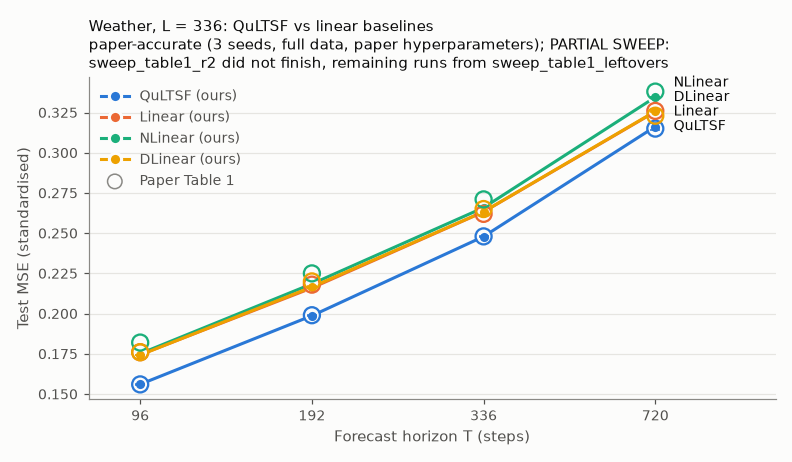

In [9]:
fig = plotting.plot_table1(comparison)
show(fig)

**Observation.** Our QuLTSF test MSE is within 0.0013 of Table 1 at every
horizon, and the three seeds agree to within 0.0001-0.002. Seed 2021, the
paper's seed, gives 0.1559 / 0.1990 / 0.2476 / 0.3154 against the paper's
0.156 / 0.199 / 0.248 / 0.315.

**Inference.** The model, data pipeline and training protocol are
implemented as in the paper.

**Remaining uncertainty.** None material for the values themselves.

**Claim impact.** Table 1's QuLTSF numbers are **quantitatively
reproduced**.

## 8. Fair baseline comparison (stored full runs)

The paper's Table 1 quotes the linear baselines from Zeng et al., who
trained them for 10 epochs with patience 3, while QuLTSF got up to 100
epochs with patience 20. We reran the baselines on our pipeline under
**both** budgets, with 3 seeds.

How each comparison is set up:

| Dimension | QuLTSF vs same-budget linear models | QuLTSF vs parameter-matched MLP |
|---|---|---|
| Information and inputs | Same: identical windows, all 21 channels, channel-independent | Same |
| Parameter count | **Not matched**: 346k vs 32k-485k | Matched to within 0.05%: 346,063 vs 346,234 at T = 96 |
| Training data | Same splits, train-fitted scaler | Same |
| Optimisation steps | Same rule (up to 100 epochs, patience 20); actual epochs differ through early stopping | Same rule |
| Tuning budget | None for any model: all use the paper's hyperparameters | None |
| Compute and wall time | Not matched (QuLTSF 84-113 min per run vs 2.5-25 min) | Not matched (MLP 11-14 min) |
| Evaluation protocol | Same: best-validation checkpoint, full test set, same seeds | Same |

**Decision rule, fixed before any result.** QuLTSF is *better* only if its
mean test MSE is lower by more than twice the larger seed std **and** a
Diebold-Mariano test on the per-window errors gives p < 0.05. *Worse* is
defined symmetrically; anything else is a *tie*. Test windows overlap by
$T - 1$ steps, so the DM test uses a lag window of $T$.

In [10]:
keep = ["linear", "nlinear", "dlinear", "linear_ltsf_budget", "nlinear_ltsf_budget", "dlinear_ltsf_budget", "mlp"]
rows_out = []
for block in fair["horizons"]:
    for row in block["rows"]:
        if row["provenance"] == "local" and row["system"] in keep and row.get("successful_runs"):
            verdict = row["qultsf_vs_system"]
            rows_out.append({
                "T": block["T"], "system": row["system"], "runs": row["successful_runs"],
                "test MSE": row["mse_mean"], "seed std": row["mse_std"],
                "params": row["trainable_parameters"],
                "QuLTSF margin": verdict["margin"], "DM p": verdict["dm_p_value"],
                "QuLTSF vs system": verdict["verdict"],
            })
display(pd.DataFrame(rows_out).set_index(["T", "system"]))

runs  test MSE    seed std  params  QuLTSF margin  \
T   system                                                                   
96  linear                  3    0.1744  4.6150e-04   32352         0.0184   
    nlinear                 3    0.1751  2.3868e-04   32352         0.0190   
    dlinear                 3    0.1743  5.7328e-05   64704         0.0182   
    linear_ltsf_budget      3    0.1769  6.2642e-04   32352         0.0208   
    nlinear_ltsf_budget     3    0.1805  6.2109e-04   32352         0.0244   
    dlinear_ltsf_budget     3    0.1751  4.1358e-04   64704         0.0190   
    mlp                     3    0.1601  4.8108e-04  346063         0.0040   
192 linear                  3    0.2160  7.0202e-04   64704         0.0173   
    nlinear                 3    0.2185  2.3876e-04   64704         0.0198   
    dlinear                 3    0.2166  3.1309e-04  129408         0.0179   
    linear_ltsf_budget      3    0.2180  1.2578e-03   64704         0.0193   
    nlinear_ltsf_budget     3    0.2238  1.1936e-03   64704         0.0251   
    dlinear_ltsf_budget     3    0.2169  1.2336e-03  129408         0.0182   
336 linear                  3    0.2633  1.4892e-03  113232         0.0153   
    nlinear                 3    0.2659  3.0322e-04  113232         0.0179   
    dlinear                 3    0.2634  2.0067e-03  226464         0.0154   
    linear_ltsf_budget      3    0.2631  7.3116e-04  113232         0.0151   
    nlinear_ltsf_budget     3    0.2702  3.1204e-04  113232         0.0222   
    dlinear_ltsf_budget     3    0.2624  1.1245e-03  226464         0.0145   
720 linear                  3    0.3255  8.4401e-04  242640         0.0092   
    nlinear                 3    0.3346  1.6710e-04  242640         0.0183   
    dlinear                 3    0.3258  4.4713e-04  485280         0.0095   
    linear_ltsf_budget      3    0.3260  5.5478e-04  242640         0.0097   
    nlinear_ltsf_budget     3    0.3385  2.8542e-04  242640         0.0222   
    dlinear_ltsf_budget     3    0.3272  4.2297e-03  485280         0.0109   
    mlp                     3    0.3252  3.2791e-03  352701         0.0089   

                               DM p QuLTSF vs system  
T   system                                            
96  linear               4.0251e-08           better  
    nlinear              1.2141e-07           better  
    dlinear              6.4734e-08           better  
    linear_ltsf_budget   1.4912e-09           better  
    nlinear_ltsf_budget  1.4709e-10           better  
    dlinear_ltsf_budget  2.1966e-08           better  
    mlp                  2.4353e-03           better  
192 linear               2.0098e-04           better  
    nlinear              1.5610e-04           better  
    dlinear              2.3267e-04           better  
    linear_ltsf_budget   6.7535e-05           better  
    nlinear_ltsf_budget  5.8375e-06           better  
    dlinear_ltsf_budget  1.4929e-04           better  
336 linear               9.0099e-03           better  
    nlinear              1.7400e-02           better  
    dlinear              6.8349e-03           better  
    linear_ltsf_budget   8.3739e-03           better  
    nlinear_ltsf_budget  4.8575e-03           better  
    dlinear_ltsf_budget  1.1208e-02           better  
720 linear               1.3048e-01              tie  
    nlinear              9.5998e-02              tie  
    dlinear              1.2204e-01              tie  
    linear_ltsf_budget   1.0173e-01              tie  
    nlinear_ltsf_budget  4.7827e-02           better  
    dlinear_ltsf_budget  8.3907e-02              tie  
    mlp                  7.8150e-04           better

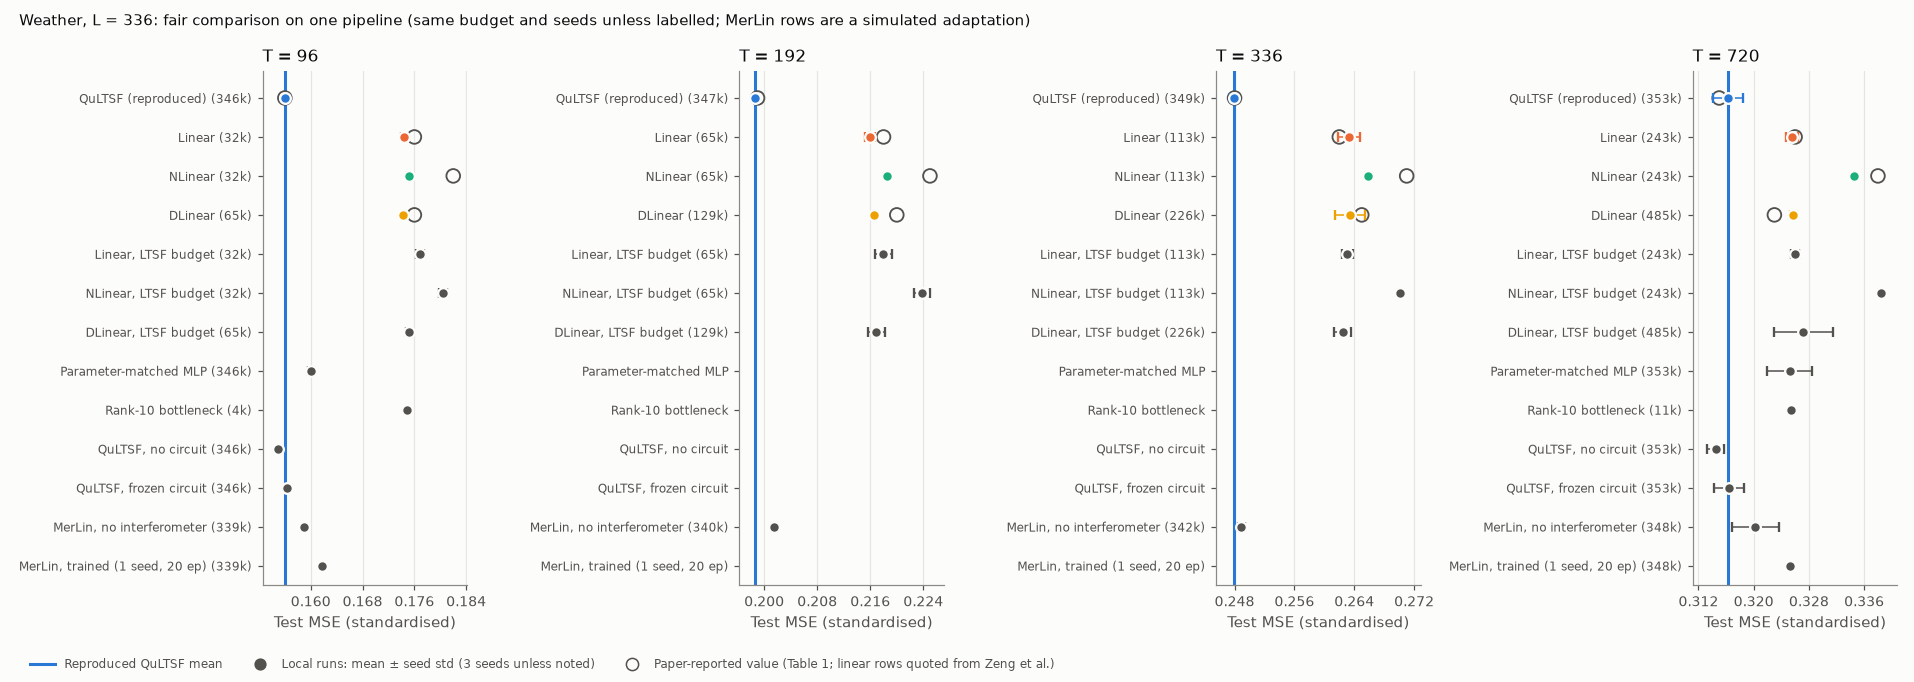

In [11]:
fig = plotting.plot_fair_comparison(fair)
show(fig)

**Observation.** Against every linear model on the same budget, QuLTSF is
better at T = 96, 192 and 336 (margins 0.015-0.020, p ≤ 0.017) and ties at
T = 720 (margin about 0.009 but p ≥ 0.096). The verdicts are identical
against the baselines at their own LTSF budget. QuLTSF also beats the
parameter-matched MLP at T = 96 and 720. Our LTSF-budget reruns agree with
the values the paper quotes, except DLinear at T = 192 and 336, where ours
is lower.

**Inference.** QuLTSF's margin over linear models is real at short and
medium horizons. It is not caused by giving QuLTSF a bigger training
budget, nor simply by having more parameters.

**Remaining uncertainty.** At T = 720 the mean margin is not significant,
and on MAE, NLinear beats QuLTSF there (0.3445 vs 0.3494).

**Claim impact.** C1 is **partially supported**: it holds at T = 96-336,
with a tie at T = 720.

## 9. Controls: is the circuit what helps? (stored full runs)

These four controls, not in the paper, separate the paper's explanation
("the quantum layer") from simpler ones. All use the same pipeline, budget
and seeds, at T = 96 and 720:

- **No circuit**: QuLTSF with $U = I$, the classical normalised quadratic
  readout from Section 3.
- **Frozen circuit**: random circuit weights that are never trained.
- **Rank-10 bottleneck**: $\text{Linear}(L \to 10) \to \text{Linear}(10 \to T)$,
  the same 10-wide middle without the 1024-wide expansion.
- **Parameter-matched MLP**: a standard GELU network with QuLTSF's
  parameter count.

test MSE  seed std  params     QuLTSF vs model
T   model                                                           
96  QuLTSF              0.1561    0.0001  346234                   -
    identity_circuit    0.1549    0.0002  346144   worse (p 1.6e-05)
    frozen_circuit      0.1563    0.0002  346144       tie (p 0.096)
    rank_bottleneck     0.1749    0.0002    4426  better (p 1.5e-08)
    mlp                 0.1601    0.0005  346063   better (p 0.0024)
720 QuLTSF              0.3163    0.0022  353098                   -
    identity_circuit    0.3145    0.0013  353008     tie (p 0.00039)
    frozen_circuit      0.3164    0.0022  353008       tie (p 0.025)
    rank_bottleneck     0.3255    0.0003   11290       tie (p 0.097)
    mlp                 0.3252    0.0033  352701  better (p 0.00078)

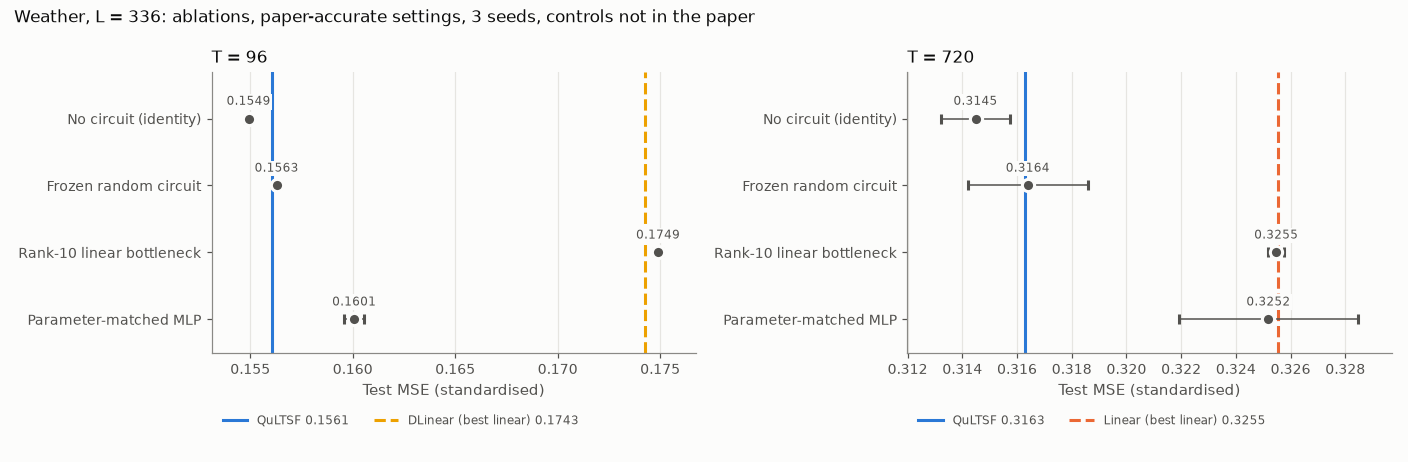

In [12]:
ablation_rows = []
for block in comparison["ablations"]:
    quantum = next(b for b in comparison["table1"] if b["T"] == block["T"])["rows"]["qultsf"]
    ablation_rows.append({"T": block["T"], "model": "QuLTSF", "test MSE": quantum["mse_mean"],
                          "seed std": quantum["mse_std"], "params": quantum["trainable_parameters"], "QuLTSF vs model": "-"})
    for name, row in block["rows"].items():
        verdict = row["qultsf_vs_control"]
        ablation_rows.append({"T": block["T"], "model": name, "test MSE": row["mse_mean"], "seed std": row["mse_std"],
                              "params": row["trainable_parameters"],
                              "QuLTSF vs model": f"{verdict['verdict']} (p {verdict['dm_p_value']:.2g})"})
display(pd.DataFrame(ablation_rows).set_index(["T", "model"]))
fig = plotting.plot_ablations(comparison)
show(fig)

**Observation.** Without its circuit, the model is *better* than QuLTSF at
T = 96 (0.1549 vs 0.1561, p = 2e-5) and ties at T = 720. A frozen random
circuit ties at both horizons. The rank-10 bottleneck only matches Linear,
and the MLP sits between Linear and QuLTSF.

**Inference.** The improvement over linear models comes from the classical
structure: expanding to 1024 features, normalising, and reading squared
values. The trained quantum circuit adds nothing measurable.

**Remaining uncertainty.** Controls ran at two horizons. A *trainable*
quadratic readout (the classical surrogate planned in Phase 1) was not run.

**Claim impact.** C3 is **unsupported**: under a fair comparison, the gain
is not attributable to the quantum layer.

## 10. Robustness and uncertainty (stored full runs)

**Seed spread.** Each dot below is one run, so the spread between seeds is
visible next to the gaps between models.

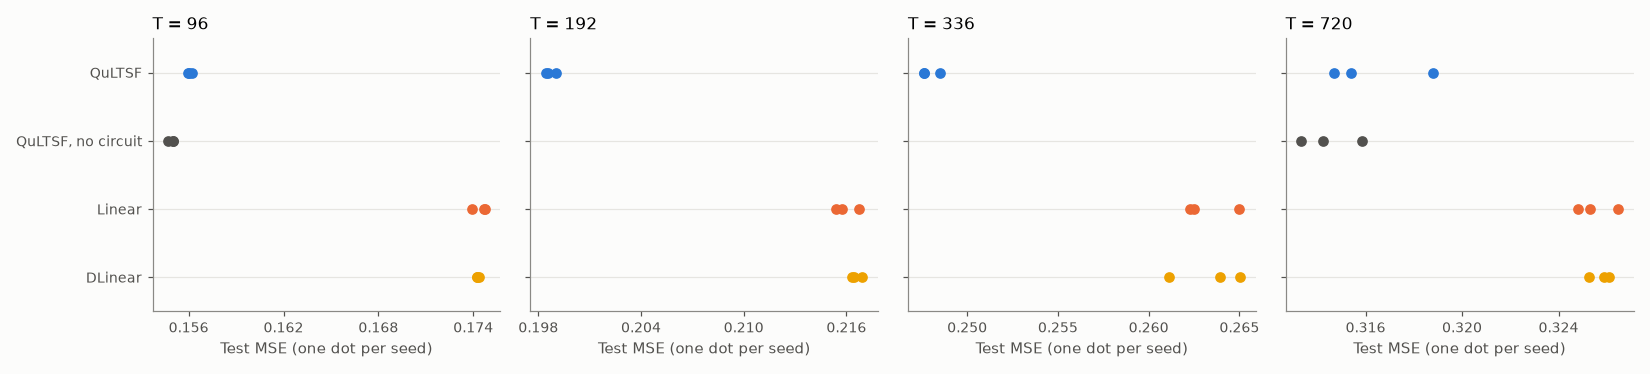

Upstream drops the last partial test batch; largest effect on MSE across Table 1 runs: 0.00028


In [13]:
models = {"qultsf": "QuLTSF", "identity_circuit": "QuLTSF, no circuit", "linear": "Linear", "dlinear": "DLinear"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), facecolor=plotting.SURFACE)
for ax, horizon in zip(axes, (96, 192, 336, 720)):
    plotting._style_axes(ax)
    for position, (name, label) in enumerate(models.items()):
        values = runs[(runs.model == name) & (runs.seq_len == 336) & (runs.pred_len == horizon)].test_mse
        colour = plotting.SERIES_COLOURS.get(name, plotting.TEXT_SECONDARY)
        ax.scatter(values, [position] * len(values), color=colour, s=36, zorder=3)
    ax.set_yticks(range(len(models)), list(models.values()) if horizon == 96 else [""] * len(models))
    ax.set_ylim(len(models) - 0.5, -0.5)
    ax.set_title(f"T = {horizon}", loc="left", fontsize=11)
    ax.set_xlabel("Test MSE (one dot per seed)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
fig.tight_layout()
show(fig)

drop = runs[runs.sweep.isin(["sweep_table1_r2", "sweep_table1_leftovers"])]
print("Upstream drops the last partial test batch; largest effect on MSE across Table 1 runs:",
      f"{(drop.test_mse - drop.test_mse_drop_last).abs().max():.5f}")

The no-circuit control was not run at T = 192 and 336, so those panels show
three models. At T = 96-336 the gaps between QuLTSF and the linear models
are many times the seed spread; at T = 720 the seeds overlap more, which
matches the "tie" verdict. Scoring the full test set instead of the
upstream truncated set changes MSE by under 0.0003.

**Lookback (claim C2; 1 seed, preliminary).** Figs 2-3 are reproduced with
one seed and no significance test.

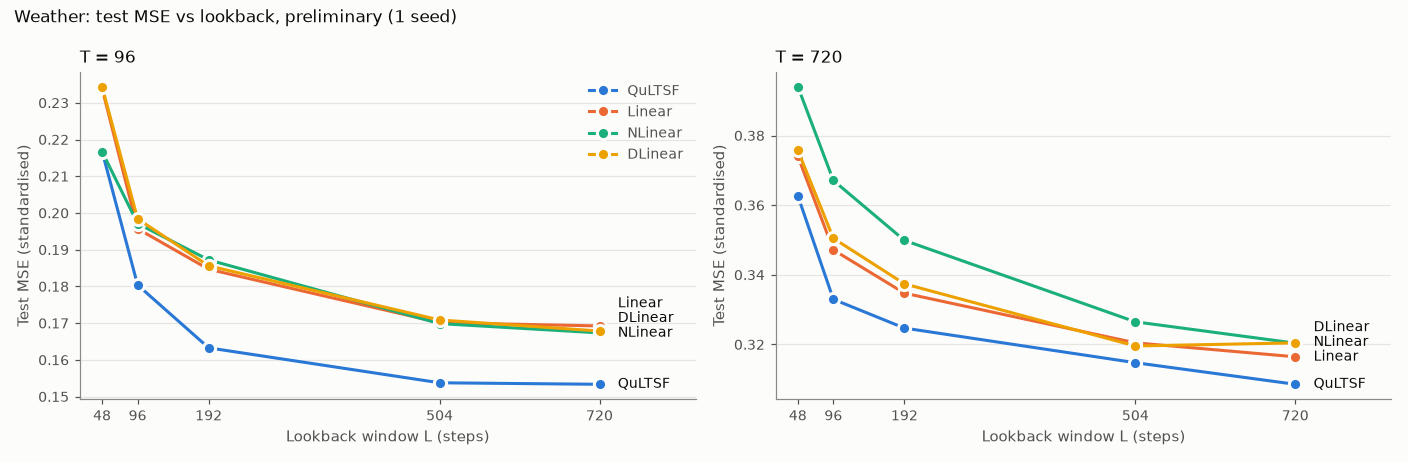

,paper,reproduced,delta,metric_agreement,trend_agreement
item,,,,,
"Fig. 2, QuLTSF, T=96, L=48",0.216,0.2168,0.0008,agrees (|Δ| ≤ 0.0020),"tie with nlinear (Δ -0.0001), as in the paper'..."
"Fig. 2, QuLTSF, T=96, L=96",0.181,0.1804,-0.0006,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 2, QuLTSF, T=96, L=192",0.163,0.1633,0.0003,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 2, QuLTSF, T=96, L=504",0.155,0.1538,-0.0012,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 2, QuLTSF, T=96, L=720",0.155,0.1534,-0.0016,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 3, QuLTSF, T=720, L=48",0.362,0.3627,0.0007,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 3, QuLTSF, T=720, L=96",0.334,0.3330,-0.0010,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 3, QuLTSF, T=720, L=192",0.325,0.3247,-0.0003,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest
"Fig. 3, QuLTSF, T=720, L=504",0.316,0.3148,-0.0012,agrees (|Δ| ≤ 0.0020),agrees: QuLTSF lowest


In [14]:
fig = plotting.plot_lookback(comparison)
show(fig)
agreement = pd.DataFrame(json.loads((RESULTS / "paper_agreement.json").read_text()))
figs = agreement[agreement["claim"] == "C2"][["item", "paper", "reproduced", "delta", "metric_agreement", "trend_agreement"]]
display(figs.set_index("item"))

**Observation.** Every model improves with longer lookback, and QuLTSF is
lowest everywhere except at L = 48, T = 96, where it ties NLinear. The
paper's own Fig. 2 shows the same tie, although its text says QuLTSF wins
"in all cases". All 10 QuLTSF values agree with those read from the
paper's plots, within about 0.002.

**Claim impact.** C2 is **partially supported, preliminary**: the trend
reproduces, but there is a single seed and one tie.

## 11. Photonic adaptation with MerLin

*An adaptation, not part of the paper; simulation only.* Phase 3 showed
that the useful part of QuLTSF is a normalised high-dimensional embedding
read by quadratic forms. The photonic version keeps that, using MerLin:

```text
x[336] -> Linear(336 -> 1001) -> L2 normalise
       -> amplitudes over the 1001 collision-free states of 4 photons in 14 modes
       -> trainable universal interferometer (182 phases)
       -> click probability of each mode (threshold detectors) -> Linear(14 -> T)
```

**Live known-answer checks** on a small 6-mode, 3-photon version, then the
full-size model on one real batch.

In [15]:
import merlin as ml
import perceval as pcvl
from merlin.core.computation_space import ComputationSpace
from merlin.measurement import MeasurementStrategy

from papers.QuLTSF.lib.qultsf_merlin import PhotonicAmplitudeLayer, QuLTSFMerlin, unbunched_occupancy

empty = ml.QuantumLayer(circuit=pcvl.Circuit(6), n_photons=3,
                        measurement_strategy=MeasurementStrategy.mode_expectations(ComputationSpace.UNBUNCHED))
occupancy = unbunched_occupancy(6, 3)
basis_readout = empty(torch.eye(occupancy.shape[0]).to(torch.complex64))
print("MerLin basis order == itertools.combinations:", bool(torch.allclose(basis_readout.double(), occupancy, atol=1e-6)))

torch.manual_seed(0)
x = torch.randn(4, 20)
no_mesh = PhotonicAmplitudeLayer(6, 3, "identity", torch.float32)(x)
merlin_empty = empty((x / x.norm(dim=-1, keepdim=True)).to(torch.complex64))
print("no-interferometer layer == MerLin empty circuit:", bool(torch.allclose(no_mesh, merlin_empty, atol=1e-6)))
trained = PhotonicAmplitudeLayer(6, 3, "trainable", torch.float32)
print("click probabilities sum to the photon number:", trained(x).sum(dim=-1).tolist())

photonic = build_model(paper_config("table1_qultsf_merlin"), torch.float32)
with torch.no_grad():
    out = photonic(inputs[:2])
print("full-size photonic model: parameters", count_trainable_parameters(photonic), "| forecast shape", tuple(out.shape))

MerLin basis order == itertools.combinations: True
no-interferometer layer == MerLin empty circuit: True
click probabilities sum to the photon number: [3.0, 3.000000238418579, 3.000000238418579, 2.999999761581421]
full-size photonic model: parameters 338959 | forecast shape (2, 96, 21)


**Stored results.** Exact simulation of the trained interferometer costs
about 9 minutes per epoch on an L4, so it ran at **reduced scope**: T = 96
and 720, seed 2021, capped at 20 epochs. The no-interferometer photonic
model needs no optical simulation and ran at full scale (all horizons,
3 seeds, full budget).

runs  test MSE  seed std  QuLTSF  \
T   model                                                              
96  qultsf_merlin_e20                  1    0.1617       NaN  0.1561   
    identity_interferometer_merlin     3    0.1590    0.0002  0.1561   
192 identity_interferometer_merlin     3    0.2015    0.0003  0.1987   
336 identity_interferometer_merlin     3    0.2489    0.0005  0.2479   
720 qultsf_merlin_e20                  1    0.3252       NaN  0.3163   
    identity_interferometer_merlin     3    0.3203    0.0034  0.3163   

                                            vs QuLTSF      vs best linear  
T   model                                                                  
96  qultsf_merlin_e20               worse (p 8.1e-07)  better (p 0.00063)  
    identity_interferometer_merlin    worse (p 0.004)  better (p 2.3e-05)  
192 identity_interferometer_merlin  worse (p 0.00098)    better (p 0.005)  
336 identity_interferometer_merlin       tie (p 0.29)    better (p 0.027)  
720 qultsf_merlin_e20               worse (p 2.9e-05)        tie (p 0.96)  
    identity_interferometer_merlin    tie (p 0.00065)        tie (p 0.43)

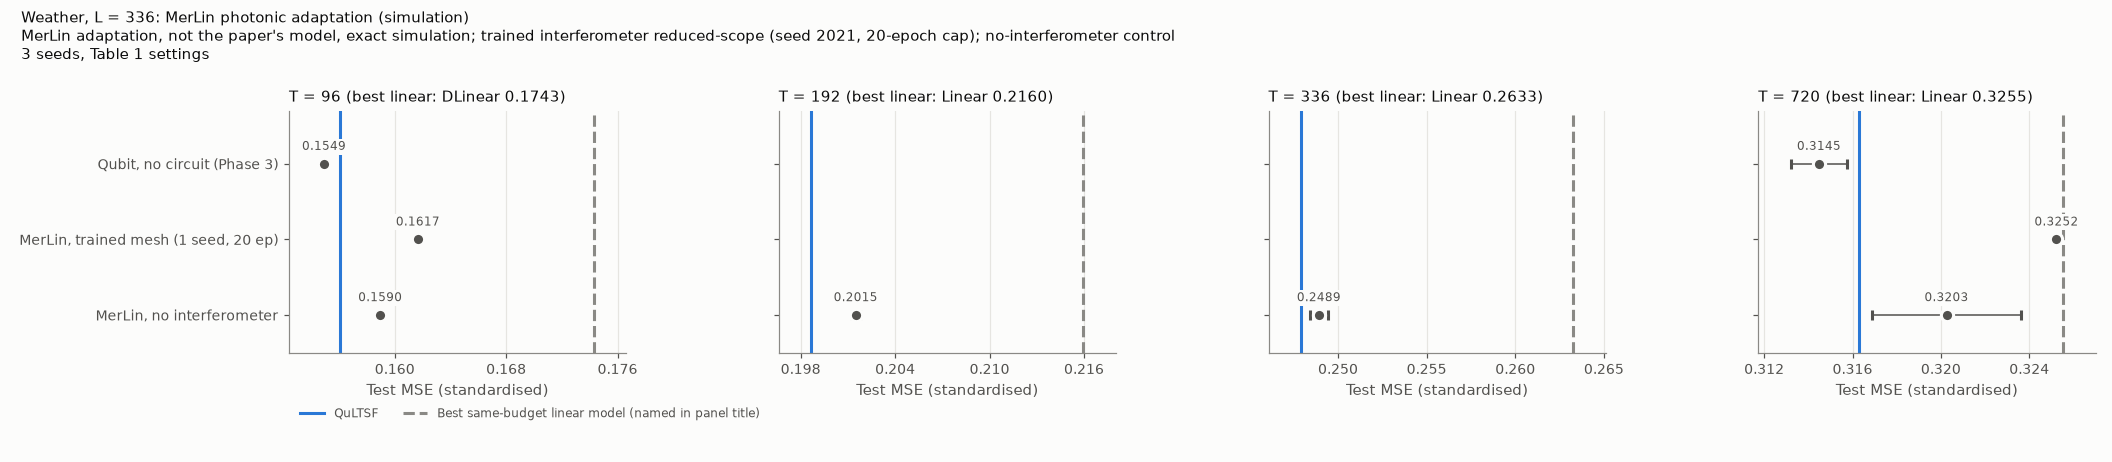

In [16]:
photonic_rows = []
for block in comparison["photonic"]:
    quantum = next(b for b in comparison["table1"] if b["T"] == block["T"])["rows"]["qultsf"]
    for name, row in block["rows"].items():
        photonic_rows.append({
            "T": block["T"], "model": name, "runs": row["n_runs"], "test MSE": row["mse_mean"], "seed std": row["mse_std"],
            "QuLTSF": quantum["mse_mean"],
            "vs QuLTSF": f"{row['vs_qultsf']['verdict']} (p {row['vs_qultsf']['dm_p_value']:.2g})",
            "vs best linear": f"{row['vs_best_baseline']['verdict']} (p {row['vs_best_baseline']['dm_p_value']:.2g})",
        })
display(pd.DataFrame(photonic_rows).set_index(["T", "model"]))
fig = plotting.plot_photonic(comparison)
show(fig)

| Setting | Value |
|---|---|
| Computation space / detector | UNBUNCHED / threshold |
| Photons / modes | 4 / 14 (1001 collision-free basis states) |
| Encoding | amplitude encoding of the normalised `Linear(336 -> 1001)` output |
| Measurement | `MeasurementStrategy.mode_expectations(UNBUNCHED)`, 14 click probabilities |
| Postselection | collision-free outputs, renormalised per input basis state (MerLin UNBUNCHED) |
| Simulator | MerLin exact simulation (merlinquantum 0.4.2, Perceval 1.3.1), NVIDIA L4; no shots; exact gradients |
| Seeds | trained mesh 2021; no interferometer 2021-2023 |

**Observation.** The no-interferometer photonic model beats the best linear
model at T = 96, 192 and 336, and ties at 720, the same pattern as QuLTSF.
It trails QuLTSF by about 0.003 at T = 96 and 192 and ties it at 336 and
720. The trained interferometer is worse than the no-interferometer model
at T = 96 and ties at 720.

**Inference.** The photonic embedding keeps most of the useful structure.
As with qubits, training the optical circuit does not help.

**Remaining uncertainty.** The trained mesh has one seed and stopped at the
20-epoch cap (best epochs 18 and 15), so it may be under-trained.
Preparing an arbitrary 1001-amplitude 4-photon state is not possible on
current hardware, so none of this is hardware validation.

**Claim impact (adaptation).** The structure carries over to photonics in
simulation; there is no evidence of a photonic advantage.

## 12. Conclusion

**Limitations.**

- **Reduced budgets:** the lookback study has 1 seed. The trained MerLin
  interferometer has 1 seed, 20 epochs, and T = 96 and 720 only. The live
  experiment (Section 6) uses 400 batches.
- **Data:** none substituted; the real Weather benchmark is used
  throughout. Only Weather is tested, as in the paper.
- **Simulator differences:** the circuit is simulated in PyTorch (checked
  against PennyLane in Section 4a). The photonic model is noiseless, exact
  MerLin simulation with MerLin's UNBUNCHED postselection.
- **Preprocessing:** the full test set is scored, where upstream drops up
  to 15 windows (effect under 0.0003 MSE).
- **Incomplete sweeps:** the Table 1 sweep record is labelled PARTIAL
  (all 52 runs completed via a retry sweep).
- **Missing controls:** a trainable quadratic readout was not run, and the
  controls cover T = 96 and 720 only.
- **Unexecuted experiments:** the transformer baselines and the
  PatchTST/MTST comparison (quoted in the paper) were not rerun.
- **Qualitative only:** Figs 2-3 values were read from plots (±0.002).

**Separating the outcomes.**

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes | Sections 4-6, 11 (live) |
| Does the method solve the task? | Yes: far better than persistence, competitive with the best linear models | Sections 4d, 7 |
| Does the paper's metric reproduce? | Yes, within 0.0013 MSE at every horizon | Section 7 |
| Does the paper's explanation survive controls? | No: the circuit-free model does as well | Section 9 |
| Does the method beat a fair baseline? | Yes at T = 96-336; tie at T = 720 | Section 8 |

**1. What reproduced.** Table 1's QuLTSF values (Section 7), the quoted
baseline values except two DLinear entries (Section 8), and the lookback
trend of Figs 2-3 (Section 10).

**2. What did not reproduce.** The attribution of the gain to the quantum
layer (claim C3): the same model without its circuit is as good or better
(Section 9). Also the claim of a win at every lookback: there is one tie,
which the paper's own figure also shows (Section 10).

**3. What remains unresolved.** Whether QuLTSF beats linear models at
T = 720 (tie, Section 8). Whether a trained photonic interferometer helps
at full budget (Section 11).

**4. What was not attempted.** The transformer, PatchTST and MTST
comparisons; other datasets; hardware execution.

**5. Reproduction verdict.** *Partially reproduced.* The numbers reproduce
quantitatively, and QuLTSF beats fairly trained linear baselines at short
and medium horizons. But the improvement comes from a classical normalised
quadratic readout, not from the quantum circuit.

**6. Photonic verdict.** *MerLin adaptation implemented (simulation,
reduced scope for the trained interferometer).* The photonic embedding
keeps most of the gain over linear models, and training the interferometer
does not add to it. No photonic advantage is shown.

In [17]:
print(f"Notebook ran in {time.perf_counter() - NOTEBOOK_START:.0f} s on CPU.")

Notebook ran in 105 s on CPU.
